# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

THE ABOVE LINK IS JUST FOR REFERENCE - PLEASE DO NOT USE THE DATASET PROVIDED IN THE ABOVE WEBPAGE FOR SOLVING THE ASSIGNMENT.

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [209]:
# Import warnings
import warnings

In [210]:
# Import the libraries you will be using for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [211]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 1.26.4
pandas version: 2.2.2
matplotlib version: 3.10.0
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [212]:
df = pd.read_parquet("/Users/inirala/Documents/Job Lookup/AIML LJMU/2. Data Analysis and Exploration'/EDA_assignment/data_NYC_taxi/2023-1.parquet")
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3041714 entries, 0 to 3066765
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            floa

How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [ ]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload

In [213]:
# from google.colab import drive
#drive.mount('/content/drive')
import os
os.chdir('/Users/inirala/Documents/Job Lookup/AIML LJMU/2. Data Analysis and Exploration\'/EDA_assignment/data_NYC_taxi/')
file_list = os.listdir()
print(file_list)

['2023-12.parquet', '2023-6.parquet', '2023-7.parquet', '.DS_Store', 'sampled_data.parquet', '2023-5.parquet', '2023-11.parquet', '2023-10.parquet', '2023-4.parquet', '2023-1.parquet', '2023-8.parquet', '2023-9.parquet', '2023-2.parquet', '2023-3.parquet']


In [214]:
# Take a small percentage of entries from each hour of every date.
# Iterating through the monthly data:
#   read a month file -> day -> hour: append sampled data -> move to next hour -> move to next day after 24 hours -> move to next month file
# Create a single dataframe for the year combining all the monthly data

# Select the folder having data files
import os

# Select the folder having data files
os.chdir('/Users/inirala/Documents/Job Lookup/AIML LJMU/2. Data Analysis and Exploration\'/EDA_assignment/data_NYC_taxi/')

# Create a list of all the twelve files to read
file_list = os.listdir()

# initialise an empty dataframe
df = pd.DataFrame()


# iterate through the list of files and sample one by one:
for file_name in file_list:
    try:
        # file path for the current file
        file_path = os.path.join(os.getcwd(), file_name)

        # Reading the current file
        df_current = pd.read_parquet(file_path)
        df_current['tpep_pickup_datetime'] = pd.to_datetime(df_current['tpep_pickup_datetime'])


        # We will store the sampled data for the current date in this df by appending the sampled data from each hour to this
        # After completing iteration through each date, we will append this data to the final dataframe.
        sampled_data = pd.DataFrame()

        # Loop through dates and then loop through every hour of each date
        for date, df_date in df_current.groupby(df_current['tpep_pickup_datetime'].dt.date):

            # Iterate through each hour of the selected date
            for hour, df_hour in df_date.groupby(df_date['tpep_pickup_datetime'].dt.hour):
                # Sample 5% of the hourly data randomly
                df_hour_sampled = df_hour.sample(frac=0.05, random_state=42)

                # add data of this hour to the dataframe
                sampled_data = pd.concat([sampled_data, df_hour_sampled], ignore_index=True)

        # Concatenate the sampled data of all the dates to a single dataframe
        df = pd.concat([df, sampled_data], ignore_index=True) # we initialised this empty DF earlier

    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

Error reading file .DS_Store: Could not open Parquet input source '<Buffer>': Parquet magic bytes not found in footer. Either the file is corrupted or this is not a parquet file.


After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [215]:
# Store the df in csv/parquet
# df.to_parquet('')
df.to_parquet('sampled_data.parquet')

## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [216]:
# Load the new data file
df = pd.read_parquet("/Users/inirala/Documents/Job Lookup/AIML LJMU/2. Data Analysis and Exploration'/EDA_assignment/data_NYC_taxi/sampled_data.parquet")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1996077 entries, 0 to 1996076
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [217]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,airport_fee
0,2,2023-11-30 23:58:12,2023-12-01 00:06:58,1.0,1.31,1.0,N,163,162,1,10.00,1.0,0.5,3.00,0.0,1.0,18.00,2.5,0.0,NaN
1,2,2023-11-30 23:58:35,2023-12-01 00:06:32,1.0,1.22,1.0,N,161,229,1,9.30,1.0,0.5,1.43,0.0,1.0,15.73,2.5,0.0,NaN
2,2,2023-12-01 00:27:51,2023-12-01 00:50:12,1.0,3.99,1.0,N,148,50,1,23.30,1.0,0.5,5.66,0.0,1.0,33.96,2.5,0.0,NaN
3,2,2023-12-01 00:38:48,2023-12-01 01:01:55,NaN,4.79,NaN,None,231,61,0,22.43,0.0,0.5,3.00,0.0,1.0,29.43,NaN,NaN,NaN
4,2,2023-12-01 00:06:19,2023-12-01 00:16:57,1.0,1.05,1.0,N,161,161,1,10.70,1.0,0.5,3.14,0.0,1.0,18.84,2.5,0.0,NaN


#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [218]:
# Fix the index and drop any columns that are not needed

df.reset_index(drop=True, inplace=True)
df.drop(columns=['store_and_fwd_flag'], inplace=True)

In [219]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,airport_fee
0,2,2023-11-30 23:58:12,2023-12-01 00:06:58,1.0,1.31,1.0,163,162,1,10.00,1.0,0.5,3.00,0.0,1.0,18.00,2.5,0.0,NaN
1,2,2023-11-30 23:58:35,2023-12-01 00:06:32,1.0,1.22,1.0,161,229,1,9.30,1.0,0.5,1.43,0.0,1.0,15.73,2.5,0.0,NaN
2,2,2023-12-01 00:27:51,2023-12-01 00:50:12,1.0,3.99,1.0,148,50,1,23.30,1.0,0.5,5.66,0.0,1.0,33.96,2.5,0.0,NaN
3,2,2023-12-01 00:38:48,2023-12-01 01:01:55,NaN,4.79,NaN,231,61,0,22.43,0.0,0.5,3.00,0.0,1.0,29.43,NaN,NaN,NaN
4,2,2023-12-01 00:06:19,2023-12-01 00:16:57,1.0,1.05,1.0,161,161,1,10.70,1.0,0.5,3.14,0.0,1.0,18.84,2.5,0.0,NaN


**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [220]:
# Combine the two airport fee columns
df["airport_fee"] = df["Airport_fee"].fillna(0) + df["airport_fee"].fillna(0)
df = df.drop(columns=["Airport_fee"])

**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [221]:
# check where values of fare amount are negative
negative_fares = df.loc[df['fare_amount'] < 0]
negative_fares.head()


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee


Did you notice something different in the `RatecodeID` column for above records?

In [304]:
# Analyse RatecodeID for the negative fare amounts
if not negative_fares.empty:
    display(negative_fares["RatecodeID"].value_counts(dropna=False))
    display(negative_fares[["fare_amount", "total_amount", "RatecodeID"]].head())
else:
    print("No negative fares in this sample.")

No negative fares in this sample.


In [223]:
# Find which columns have negative values
money_cols = ["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
    "improvement_surcharge", "total_amount", "congestion_surcharge", "airport_fee"]

df.loc[(df[money_cols] < 0).any(axis=1)]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
25600,2,2023-12-05 15:54:13,2023-12-05 15:54:37,1.0,0.00,1.0,132,132,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-1.50,0.0,0.00
49571,2,2023-12-09 08:34:26,2023-12-09 08:34:35,1.0,0.00,2.0,107,137,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
66396,2,2023-12-12 06:57:09,2023-12-12 07:16:37,1.0,3.30,1.0,164,239,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
101346,2,2023-12-17 08:10:57,2023-12-17 08:28:46,1.0,11.27,1.0,132,70,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-3.25,0.0,-1.75
113242,2,2023-12-19 15:33:14,2023-12-19 16:05:27,2.0,5.83,1.0,186,87,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1946111,2,2023-06-21 16:01:44,2023-06-21 17:11:47,1.0,12.56,2.0,132,114,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-5.75,-2.5,-1.75
1957538,2,2023-06-23 15:19:43,2023-06-23 15:36:43,1.0,2.14,1.0,142,164,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
1966801,2,2023-06-25 05:59:41,2023-06-25 06:08:22,2.0,1.09,2.0,90,170,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
1989486,2,2023-06-29 17:52:22,2023-06-29 18:11:03,1.0,2.93,1.0,246,239,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00


In [224]:
# fix these negative values 
negative_mask = (df[money_cols] < 0).any(axis=1)
print(f"Rows with negative monetary values: {negative_mask.sum()}")

df = df.loc[~negative_mask].copy()

# Confirm no negative monetary values remain
print((df[money_cols] < 0).sum())

Rows with negative monetary values: 82
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
airport_fee              0
dtype: int64


### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [225]:
# Find the proportion of missing values in each column
df.isnull().mean()

VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          0.034203
trip_distance            0.000000
RatecodeID               0.034203
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     0.034203
airport_fee              0.000000
dtype: float64

**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [226]:
# Display the rows with null values
# Impute NaN values in 'passenger_count'
df["passenger_count"] = df["passenger_count"].fillna(df["passenger_count"].mode()[0])

Did you find zeroes in passenger_count? Handle these.

**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [227]:
# Fix missing values in 'RatecodeID'
df["RatecodeID"] = df["RatecodeID"].fillna(df["RatecodeID"].mode()[0])


**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [228]:
# handle null values in congestion_surcharge
df["congestion_surcharge"] = df["congestion_surcharge"].fillna(df["congestion_surcharge"].mode()[0])

Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [229]:
# Handle any remaining missing values
df.isnull().mean()

VendorID                 0.0
tpep_pickup_datetime     0.0
tpep_dropoff_datetime    0.0
passenger_count          0.0
trip_distance            0.0
RatecodeID               0.0
PULocationID             0.0
DOLocationID             0.0
payment_type             0.0
fare_amount              0.0
extra                    0.0
mta_tax                  0.0
tip_amount               0.0
tolls_amount             0.0
improvement_surcharge    0.0
total_amount             0.0
congestion_surcharge     0.0
airport_fee              0.0
dtype: float64

### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

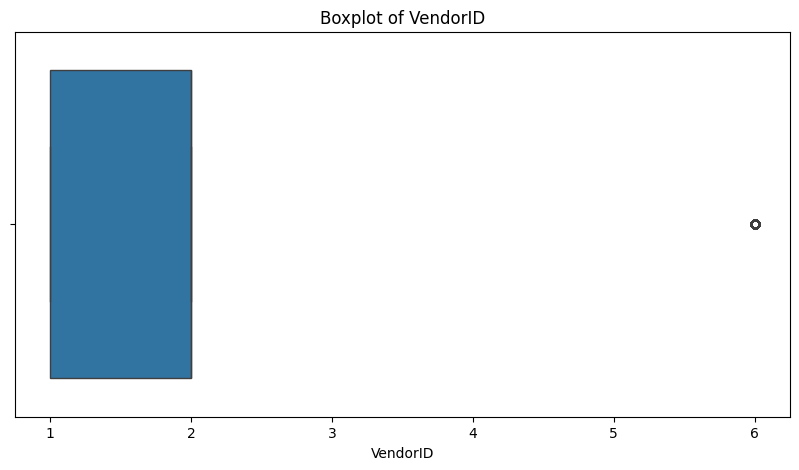

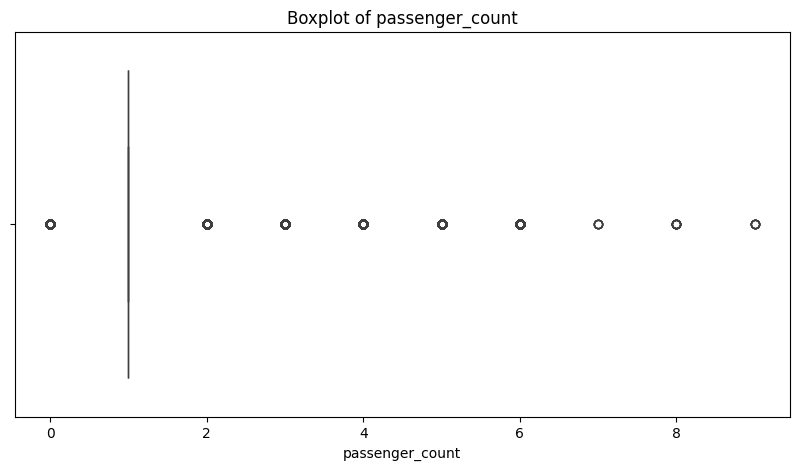

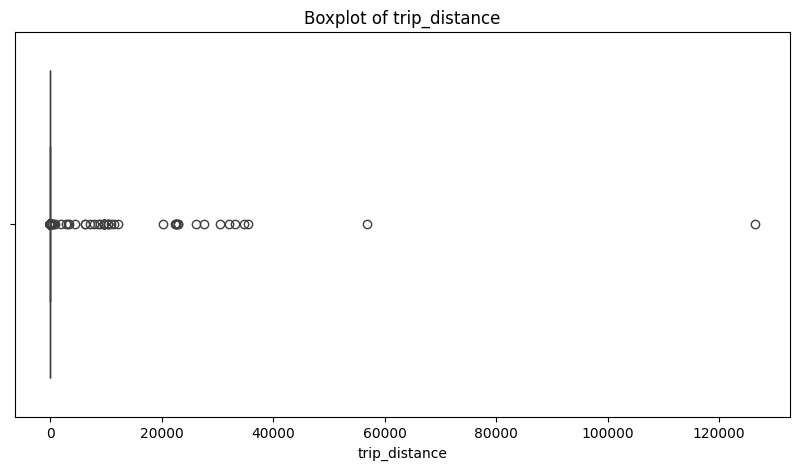

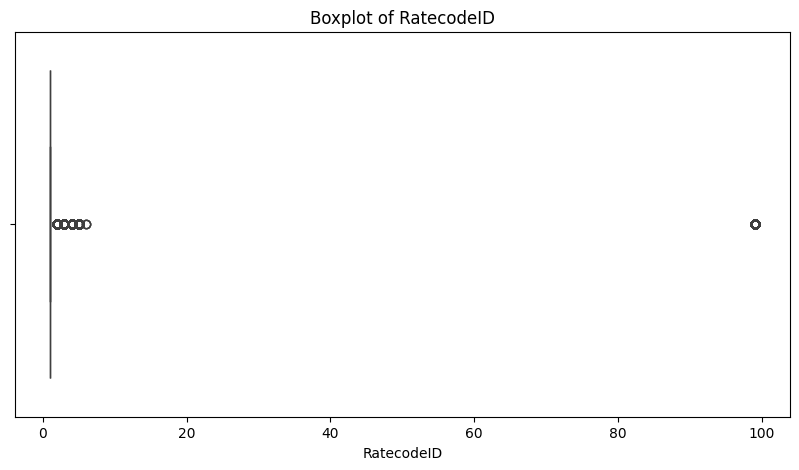

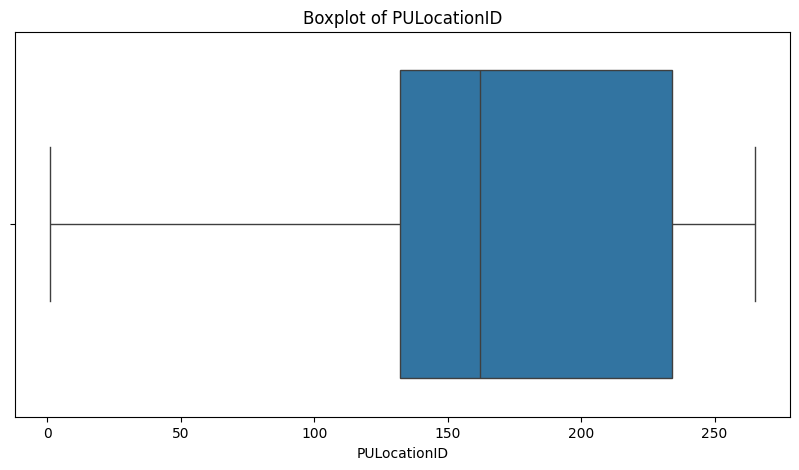

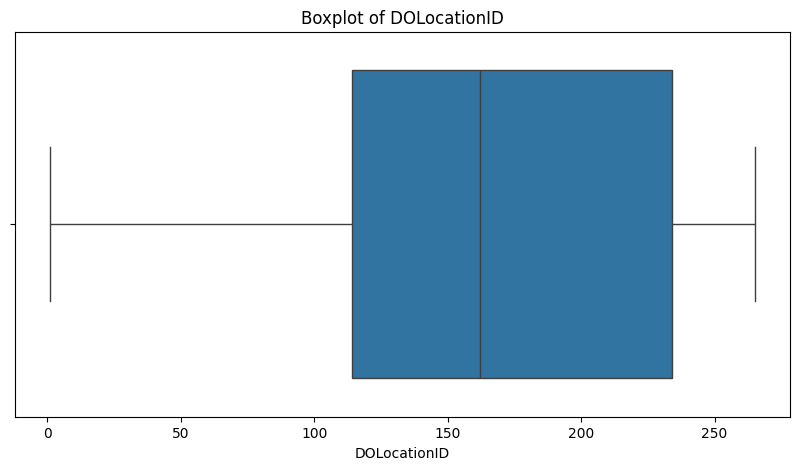

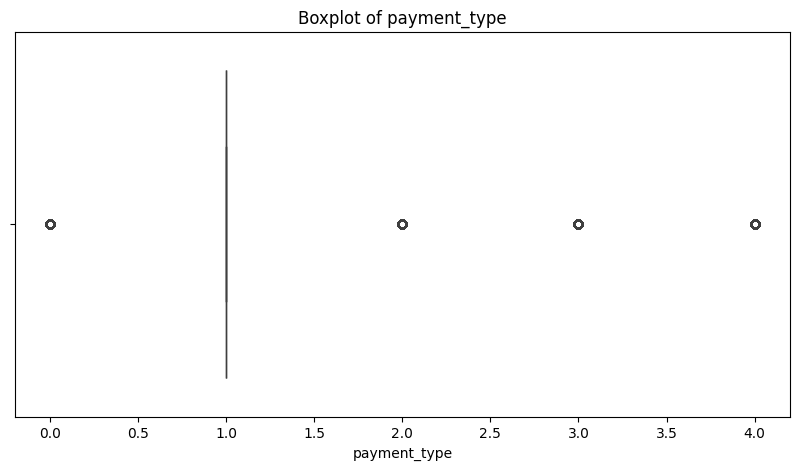

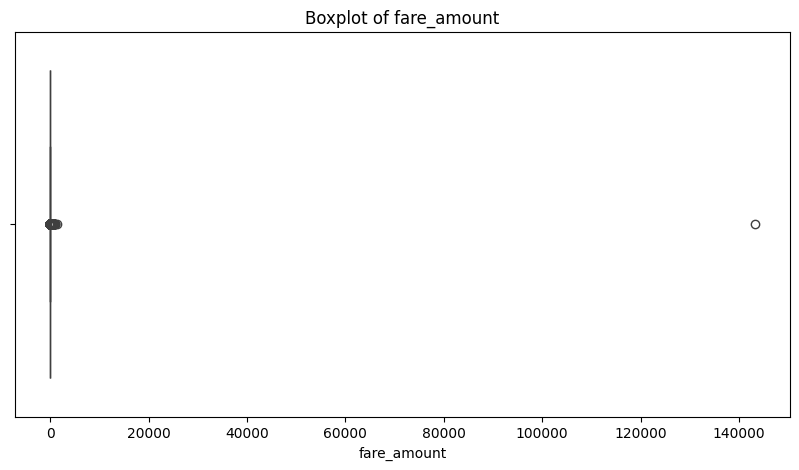

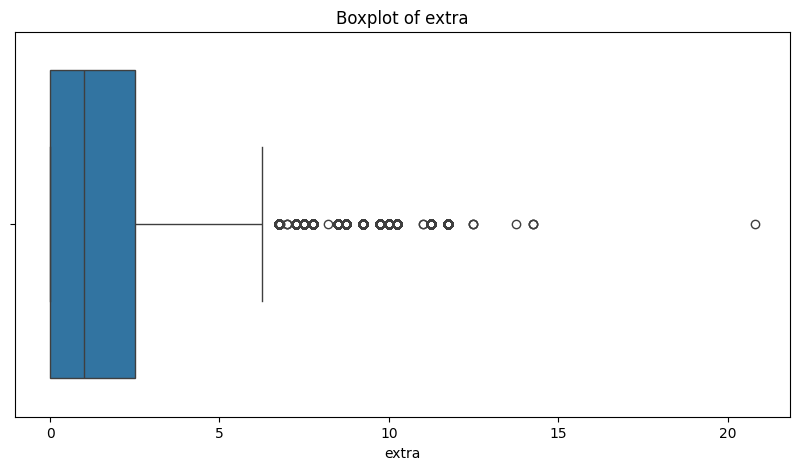

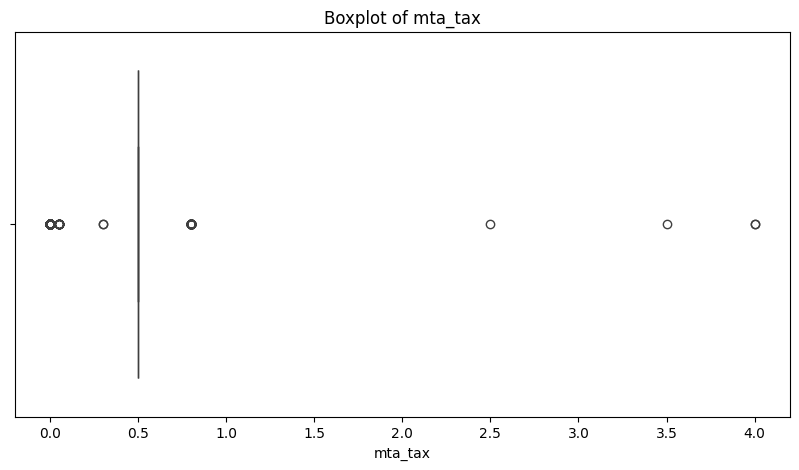

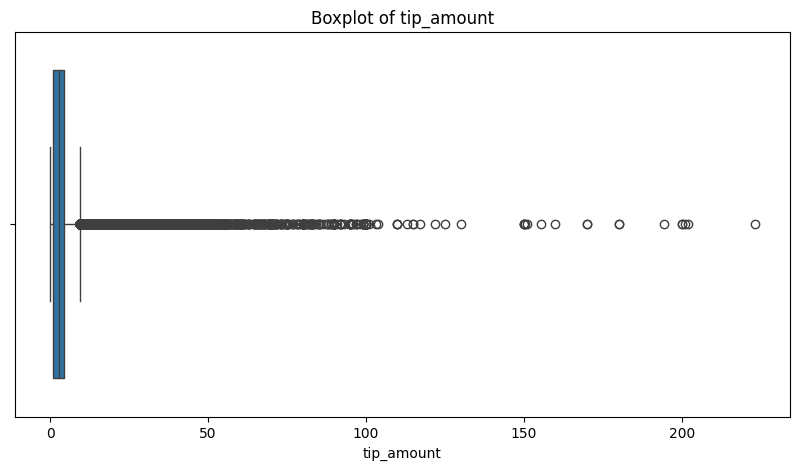

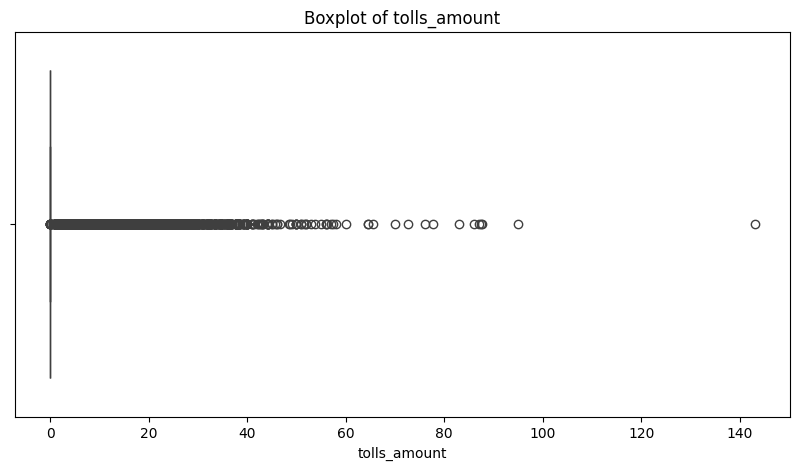

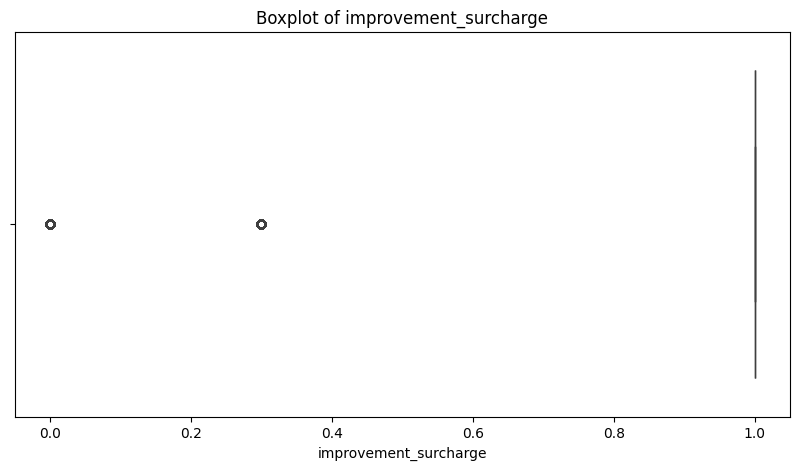

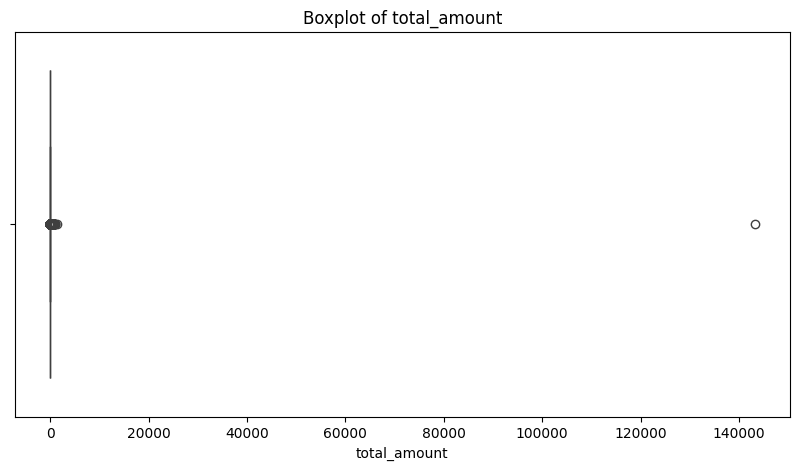

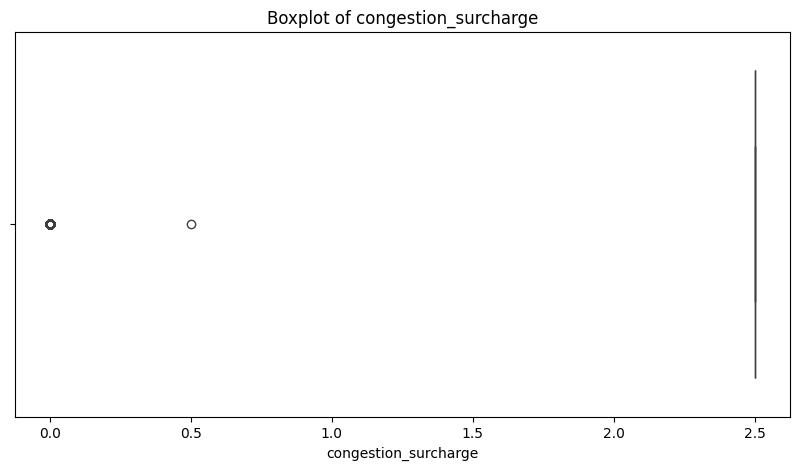

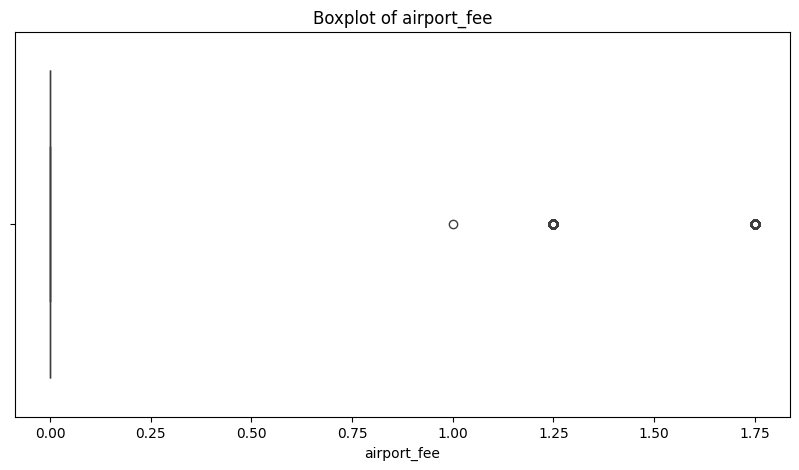

In [230]:
# Describe the data and check if there are any potential outliers present
# Check for potential out of place values in various columns
df.describe()

# Visualize potential outliers using boxplots
import matplotlib.pyplot as plt
import seaborn as sns

for column in df.select_dtypes(include=['float64', 'int64']).columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot of {column}')
    plt.show()


**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [ ]:
# remove passenger_count > 6
df = df[df['passenger_count'] <= 6].copy()

In [ ]:
# Continue with outlier handling
near_zero_trip_dist_and_high_fare = ((df["trip_distance"] <= 0.1) & (df["fare_amount"] > 300))

zero_distance_fare_different_zones = (
    (df["trip_distance"] == 0)
    & (df["fare_amount"] == 0)
    & (df["PULocationID"] != df["DOLocationID"])
)
excessive_distance = df["trip_distance"] > 250
invalid_payment_type = df["payment_type"] == 0
negative_distance = df["trip_distance"] < 0

# Combine the conditions so each row is removed only once
outlier_mask = (
    near_zero_trip_dist_and_high_fare
    | zero_distance_fare_different_zones
    | excessive_distance
    | invalid_payment_type
    | negative_distance
)

print(f"Outlier rows to remove: {outlier_mask.sum()}")
df = df.loc[~outlier_mask].copy()
df.reset_index(drop=True, inplace=True)
df.head()

Outlier rows to remove: 0


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration
1486624,1,2023-09-05 10:16:13,2023-09-05 10:20:56,1.0,0.70,1.0,249,90,2,143163.45,2.5,0.5,0.00,0.00,1.0,143167.45,2.5,0.0,4.716667
1486626,2,2023-09-05 10:14:11,2023-09-05 11:14:38,2.0,11.72,1.0,158,138,1,68.80,5.0,0.5,16.95,6.94,1.0,101.69,2.5,0.0,60.450000


In [247]:
# Do any columns need standardising?
#Didn't see any other column which require standardisation.
#highest_fare = df.sort_values("fare_amount", ascending=False).head(10)
#highest_fare

#Entry 1486624 has high fare amount 143163.45, this looks like an error. Removing this entry
df = df[df.index != 1486624].copy()
df.reset_index(drop=True, inplace=True)

# Show relationship between fare and trip duration
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"])
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])
df["trip_duration"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60  # duration in minutes

#Check entries which have trip_duration more than 2000 minutes
#df[df["trip_duration"] > 2000]

#Enteris with more than 2000 minutes looks wrong enteries.
df = df[df["trip_duration"] <= 2000].copy()
df.reset_index(drop=True, inplace=True)


In [248]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee',
 'trip_duration']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`:
* `tpep_pickup_datetime`:
* `tpep_dropoff_datetime`:
* `passenger_count`:
* `trip_distance`:
* `RatecodeID`:
* `PULocationID`:
* `DOLocationID`:
* `payment_type`:
* `pickup_hour`:
* `trip_duration`:


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`

In [198]:
#VendorID: Categorical
#tpep_pickup_datetime: Temporal
#tpep_dropoff_datetime: Temporal 
#passenger_count: Numerical
#trip_distance: Numerical
#RatecodeID: Categorical
#PULocationID: Categorical
#DOLocationID: Categorical
#payment_type: Categorical
#pickup_hour: Categorical
#trip_distance: Numerical

#The monetary variables (fare_amount, extra, mta_tax, tip_amount, tolls_amount, improvement_surcharge, total_amount, congestion_surcharge, and airport_fee) are numerical variables.

##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

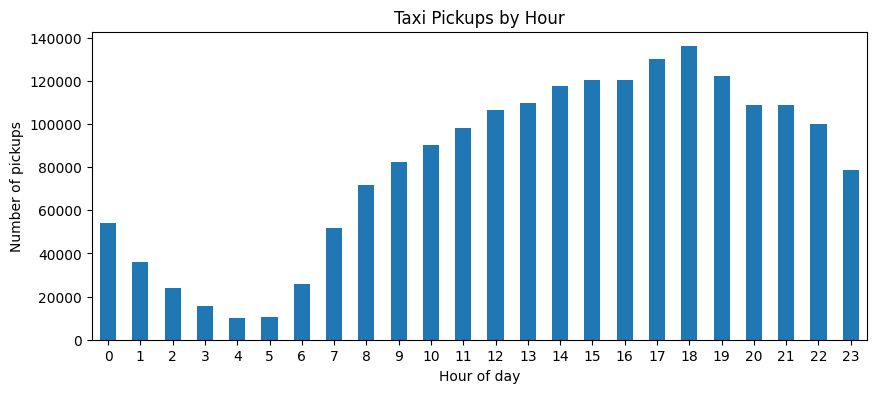

In [249]:
# Find and show the hourly trends in taxi pickups
pickup_time = pd.to_datetime(df["tpep_pickup_datetime"])
hourly_pickups = pickup_time.dt.hour.value_counts().reindex(range(24), fill_value=0)

hourly_pickups.plot(kind="bar", figsize=(10, 4), title="Taxi Pickups by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Number of pickups")
plt.xticks(range(24), rotation=0)
plt.show()

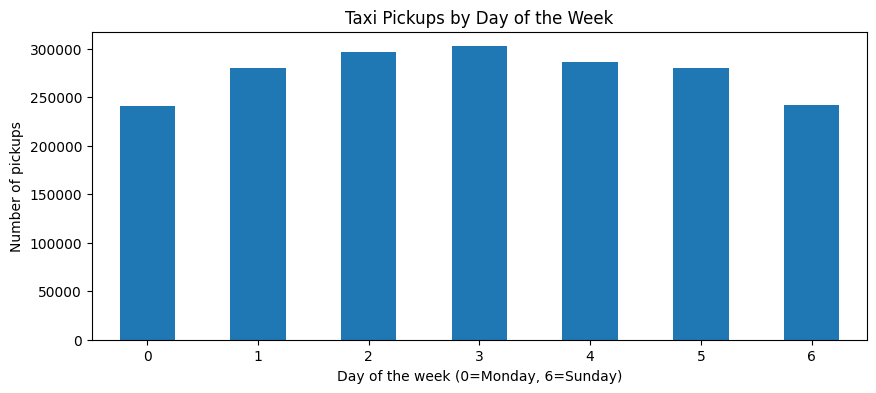

In [145]:
# Find and show the daily trends in taxi pickups (days of the week)
pickup_time = pd.to_datetime(df["tpep_pickup_datetime"])
daily_pickups = pickup_time.dt.dayofweek.value_counts().reindex(range(7), fill_value=0)

daily_pickups.plot(kind="bar", figsize=(10, 4), title="Taxi Pickups by Day of the Week")
plt.xlabel("Day of the week (0=Monday, 6=Sunday)")
plt.ylabel("Number of pickups")
plt.xticks(range(7), rotation=0)
plt.show()

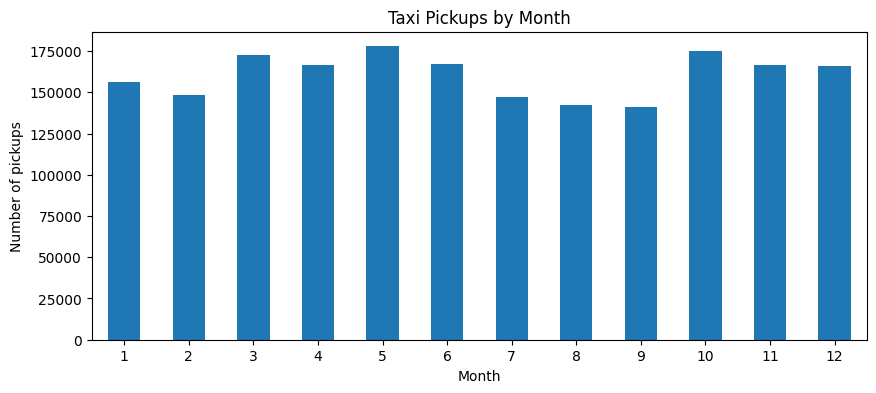

In [250]:
# Show the monthly trends in pickups
pickup_time = pd.to_datetime(df["tpep_pickup_datetime"])
monthly_pickups = pickup_time.dt.month.value_counts().reindex(range(1, 13), fill_value=0)

monthly_pickups.plot(kind="bar", figsize=(10, 4), title="Taxi Pickups by Month")
plt.xlabel("Month")
plt.ylabel("Number of pickups")
plt.xticks(range(12), rotation=0)
plt.show()

##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [251]:
# Analyse the above parameters
financial_cols = ["fare_amount", "tip_amount", "total_amount", "trip_distance"]

values_df = pd.DataFrame({
    "zero_count": (df[financial_cols] == 0).sum(),
    "negative_count": (df[financial_cols] < 0).sum()
})

display(values_df)

,zero_count,negative_count
fare_amount,534,0
tip_amount,431847,0
total_amount,276,0
trip_distance,24109,0


Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

Yes, zeroes can create problem in analysis

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?

In [307]:
# Create a df with non zero entries for the selected parameters.
analysis_df = df[
    (df["fare_amount"] > 0) &
    (df["total_amount"] > 0)
].copy()


max_fare = analysis_df["fare_amount"].max()
display(analysis_df.loc[analysis_df["fare_amount"] == max_fare])

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration
1125501,2,2023-08-18 15:28:08,2023-08-18 20:15:05,1.0,204.86,4.0,132,265,2,1375.0,0.0,0.5,0.0,56.94,1.0,1435.19,0.0,1.75,286.95


trip distance could be 0 if trip is cancelled or aborted. So we should not drop such cases.

**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

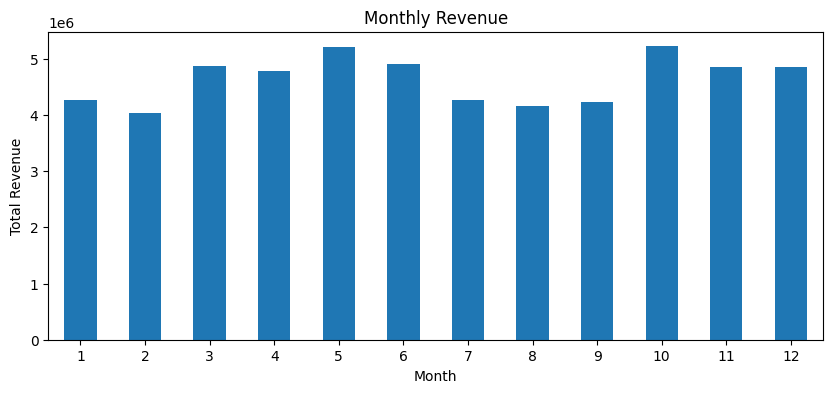

In [308]:
# Group data by month and analyse monthly revenue
pickup_time = pd.to_datetime(analysis_df["tpep_pickup_datetime"])
monthly_revenue = analysis_df.groupby(pickup_time.dt.month)["total_amount"].sum()

monthly_revenue.plot(kind="bar", figsize=(10, 4), title="Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(range(12), rotation=0)
plt.show()

**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

quarter
2022Q4    2.426611e-07
2023Q1    2.368086e-01
2023Q2    2.674772e-01
2023Q3    2.273930e-01
2023Q4    2.683210e-01
Freq: Q-DEC, Name: total_amount, dtype: float64

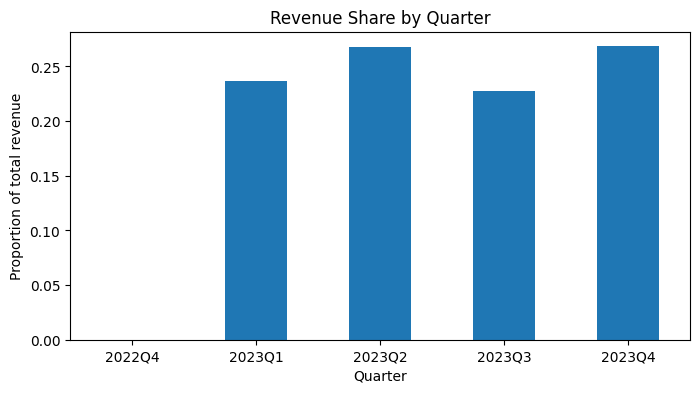

In [309]:
# Calculate proportion of each quarter
analysis_df["pickup_time"] = pd.to_datetime(analysis_df["tpep_pickup_datetime"])
analysis_df["quarter"] = analysis_df["pickup_time"].dt.to_period("Q")

quarterly_revenue = analysis_df.groupby("quarter")["total_amount"].sum()
quarterly_revenue_prop = quarterly_revenue / quarterly_revenue.sum()

display(quarterly_revenue_prop)

quarterly_revenue_prop.plot(kind="bar", figsize=(8, 4), title="Revenue Share by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Proportion of total revenue")
plt.xticks(rotation=0)
plt.show()


**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

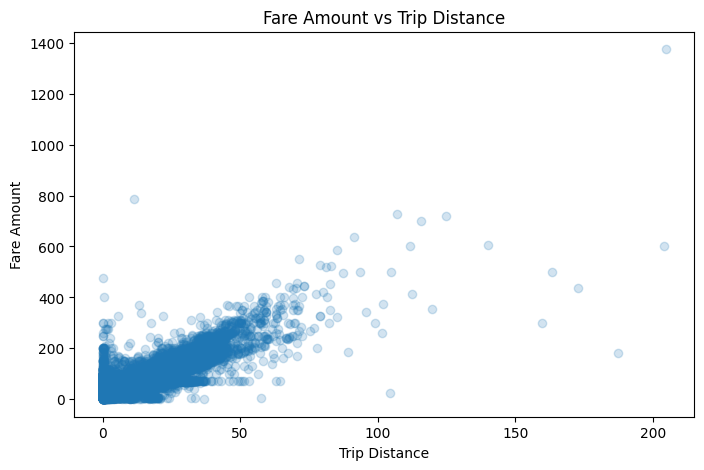

Correlation between trip_distance and fare_amount: 0.9443738765702505
Maximum fare amount: 1375.0


In [310]:
# Show how trip fare is affected by distance
distance_fare = analysis_df[analysis_df["trip_distance"] > 0][["trip_distance", "fare_amount"]].copy()

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(distance_fare["trip_distance"], distance_fare["fare_amount"], alpha=0.2)
plt.title("Fare Amount vs Trip Distance")
plt.xlabel("Trip Distance")
plt.ylabel("Fare Amount")
plt.show()

# Correlation
corr = distance_fare["trip_distance"].corr(distance_fare["fare_amount"])
print("Correlation between trip_distance and fare_amount:", corr)

max_fair = distance_fare["fare_amount"].max()
print("Maximum fare amount:", max_fair)

**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

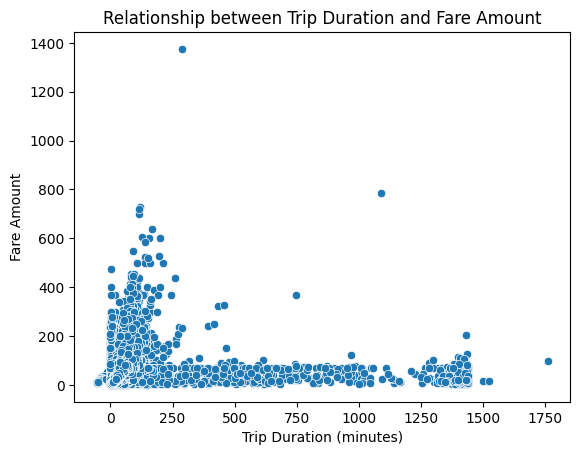

In [256]:
# Show relationship between fare and trip duration
analysis_df["tpep_dropoff_datetime"] = pd.to_datetime(analysis_df["tpep_dropoff_datetime"])
analysis_df["tpep_pickup_datetime"] = pd.to_datetime(analysis_df["tpep_pickup_datetime"])
analysis_df["trip_duration"] = (analysis_df["tpep_dropoff_datetime"] - analysis_df["tpep_pickup_datetime"]).dt.total_seconds() / 60  # duration in minutes
sns.scatterplot(x="trip_duration", y="fare_amount", data=analysis_df)
plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Fare Amount")
plt.title("Relationship between Trip Duration and Fare Amount")
plt.show()


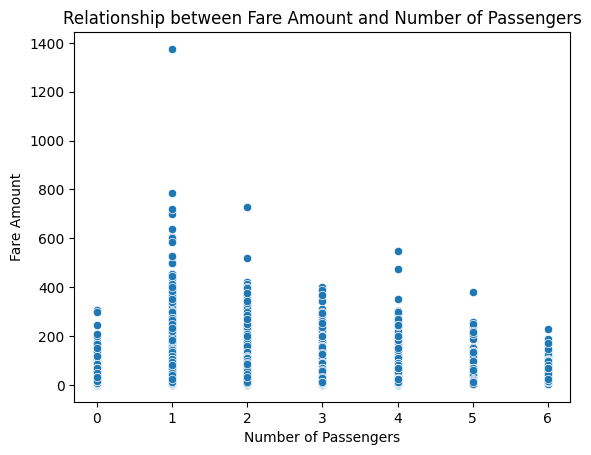

In [257]:
# Show relationship between fare and number of passengers
sns.scatterplot(x='passenger_count', y='fare_amount', data=analysis_df)
plt.title('Relationship between Fare Amount and Number of Passengers')
plt.xlabel('Number of Passengers')
plt.ylabel('Fare Amount')
plt.show()


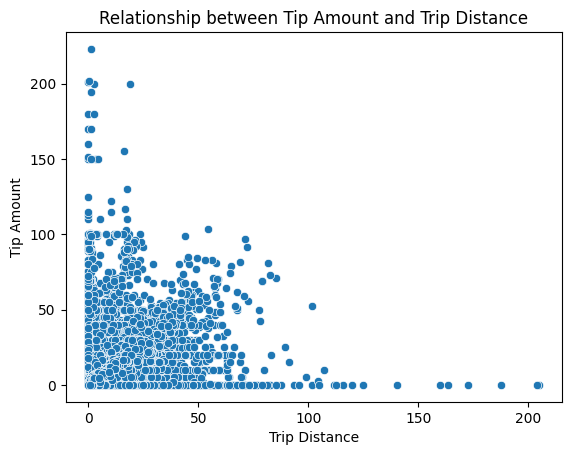

In [208]:
# Show relationship between tip and trip distance
sns.scatterplot(x='trip_distance', y='tip_amount', data=df)
plt.title('Relationship between Tip Amount and Trip Distance')
plt.xlabel('Trip Distance')
plt.ylabel('Tip Amount')
plt.show()


**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

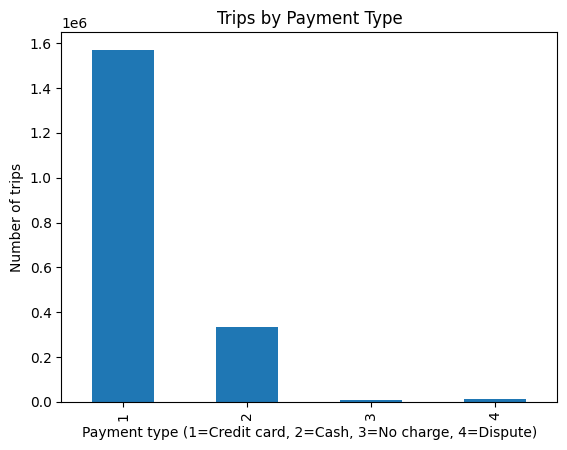

In [258]:
# Analyse the distribution of different payment types (payment_type).
payment_counts = df["payment_type"].value_counts().sort_index()

payment_counts.plot(kind="bar", title="Trips by Payment Type")
plt.xlabel("Payment type (1=Credit card, 2=Cash, 3=No charge, 4=Dispute)")
plt.ylabel("Number of trips")
plt.show()



- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [ ]:
#!pip install geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 40.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.7/24.7 MB 6.9 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 10.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 10.6 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [geopandas]/6 [geopandas]


**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [ ]:
import geopandas as gpd

# Read the shapefile using geopandas
zone_info = gpd.read_file("/Users/inirala/Documents/Job Lookup/AIML LJMU/2. Data Analysis and Exploration'/EDA_assignment/Datasets and Dictionary/taxi_zones/taxi_zones.shp")  # read the .shp file using gpd
print(zone_info.columns.tolist())

['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    object  
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    object  
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), object(2)
memory usage: 12.5+ KB
None


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

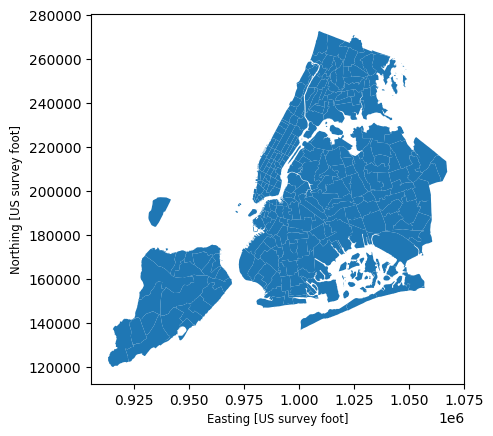

In [271]:
print(zone_info.info())
zone_info.plot()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [311]:
# Merge zones and trip records using locationID and PULocationID
analysis_df_merged = analysis_df.merge(
    zone_info,
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
)

analysis_df_merged.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration,pickup_time,quarter,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,2,2023-11-30 23:58:12,2023-12-01 00:06:58,1.0,1.31,1.0,163,162,1,10.0,1.0,0.5,3.00,0.0,1.0,18.00,2.5,0.0,8.766667,2023-11-30 23:58:12,2023Q4,163.0,0.034177,0.000041,Midtown North,163.0,Manhattan,"POLYGON ((989412.663 219020.943, 990045.841 21..."
1,2,2023-11-30 23:58:35,2023-12-01 00:06:32,1.0,1.22,1.0,161,229,1,9.3,1.0,0.5,1.43,0.0,1.0,15.73,2.5,0.0,7.950000,2023-11-30 23:58:35,2023Q4,161.0,0.035804,0.000072,Midtown Center,161.0,Manhattan,"POLYGON ((991081.026 214453.698, 990952.644 21..."
2,2,2023-12-01 00:27:51,2023-12-01 00:50:12,1.0,3.99,1.0,148,50,1,23.3,1.0,0.5,5.66,0.0,1.0,33.96,2.5,0.0,22.350000,2023-12-01 00:27:51,2023Q4,148.0,0.039131,0.000070,Lower East Side,148.0,Manhattan,"POLYGON ((988552.836 201677.665, 988387.669 20..."
3,2,2023-12-01 00:06:19,2023-12-01 00:16:57,1.0,1.05,1.0,161,161,1,10.7,1.0,0.5,3.14,0.0,1.0,18.84,2.5,0.0,10.633333,2023-12-01 00:06:19,2023Q4,161.0,0.035804,0.000072,Midtown Center,161.0,Manhattan,"POLYGON ((991081.026 214453.698, 990952.644 21..."
4,2,2023-12-01 00:16:07,2023-12-01 00:19:17,1.0,0.40,1.0,68,68,1,5.1,1.0,0.5,0.00,0.0,1.0,10.10,2.5,0.0,3.166667,2023-12-01 00:16:07,2023Q4,68.0,0.049337,0.000111,East Chelsea,68.0,Manhattan,"POLYGON ((983690.405 209040.369, 983550.612 20..."


**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [280]:
# Group data by location and calculate the number of trips
trip_counts = analysis_df_merged.groupby("PULocationID").size().reset_index(name="trip_count")
trip_counts

,PULocationID,trip_count
0,1,47
1,2,2
2,3,36
3,4,1899
4,5,9
...,...,...
250,261,9975
251,262,24773
252,263,36486
253,264,16807


**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [281]:
# Merge trip counts back to the zones GeoDataFrame
zones_with_trips = zone_info.merge(
    trip_counts,
    left_on="LocationID",
    right_on="PULocationID",
    how="left"
)

zones_with_trips["trip_count"] = zones_with_trips["trip_count"].fillna(0).astype(int)
zones_with_trips.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,PULocationID,trip_count
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19...",1.0,47
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343...",2.0,2
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2...",3.0,36
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20...",4.0,1899
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144...",5.0,9


The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

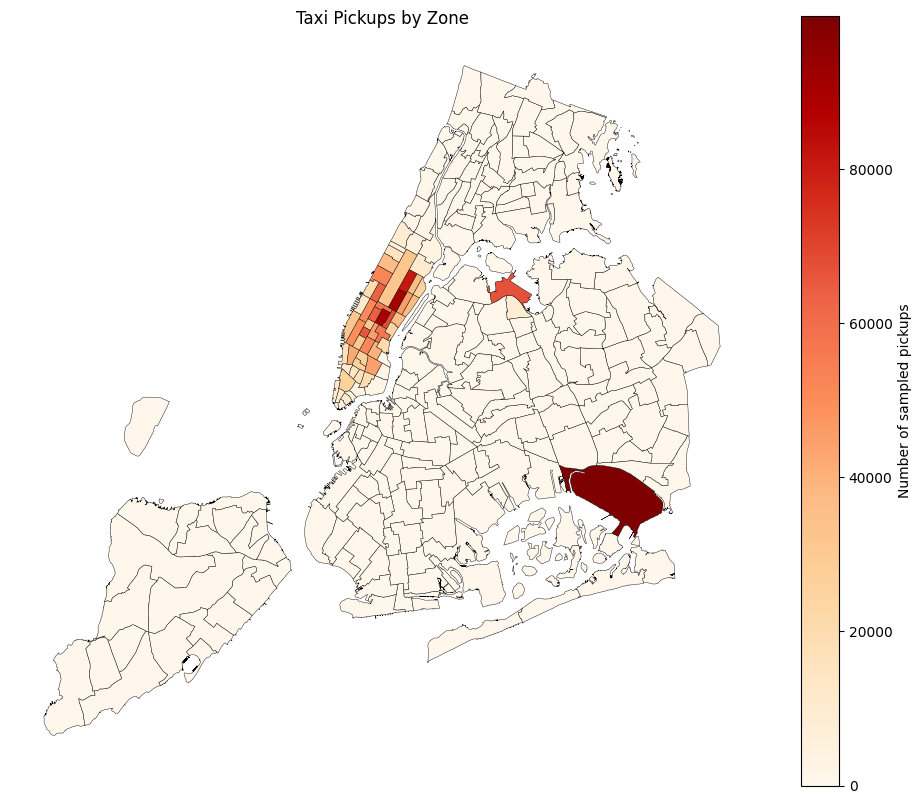

In [282]:
# Define figure and axis
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# Plot the map and display it
zones_with_trips.plot(
    column="trip_count",
    cmap="OrRd",
    linewidth=0.3,
    edgecolor="black",
    legend=True,
    legend_kwds={"label": "Number of sampled pickups", "orientation": "vertical"},
    ax=ax
)

ax.set_title("Taxi Pickups by Zone")
ax.set_axis_off()
plt.show()


In [ ]:
# can you try displaying the zones DF sorted by the number of trips?
zones_with_trips.sort_values("trip_count", ascending=False)[
    ["LocationID", "zone", "borough", "trip_count"]
]

,LocationID,zone,borough,trip_count
131,132,JFK Airport,Queens,99945
236,237,Upper East Side South,Manhattan,91005
160,161,Midtown Center,Manhattan,89874
235,236,Upper East Side North,Manhattan,81133
161,162,Midtown East,Manhattan,68705
...,...,...,...,...
220,221,Stapleton,Staten Island,0
175,176,Oakwood,Staten Island,0
244,245,West Brighton,Staten Island,0
29,30,Broad Channel,Queens,0


Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [289]:
trips = analysis_df_merged[
    (analysis_df_merged["trip_duration"] > 0)
    & (analysis_df_merged["trip_distance"] > 0)
].copy()

trips["pickup_hour"] = pd.to_datetime(trips["tpep_pickup_datetime"]).dt.hour

routes = (
    trips.groupby(["pickup_hour", "PULocationID", "DOLocationID"])
    .agg(
        avg_distance=("trip_distance", "mean"),
        avg_duration=("trip_duration", "mean"),
    )
)

routes["speed_mph"] = routes["avg_distance"] / (routes["avg_duration"] / 60)

slowest_routes = routes.loc[
    routes.groupby("pickup_hour")["speed_mph"].idxmin()
]

slowest_routes

,,,avg_distance,avg_duration,speed_mph
pickup_hour,PULocationID,DOLocationID,,,
0,74,116,2.315,686.891667,0.202215
1,258,258,0.020,45.750000,0.026230
2,144,100,2.880,1416.833333,0.121962
3,45,249,1.676,577.143333,0.174237
4,162,162,0.640,357.358333,0.107455
5,142,142,0.560,1413.550000,0.023770
6,70,138,1.490,1042.566667,0.085750
7,13,209,0.860,709.741667,0.072703
8,100,7,0.220,334.433333,0.039470


How does identifying high-traffic, high-demand routes help us?

It will help use to position more cabs where high demand is there. Slow routes help us to know high traffic bottlenecks.

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

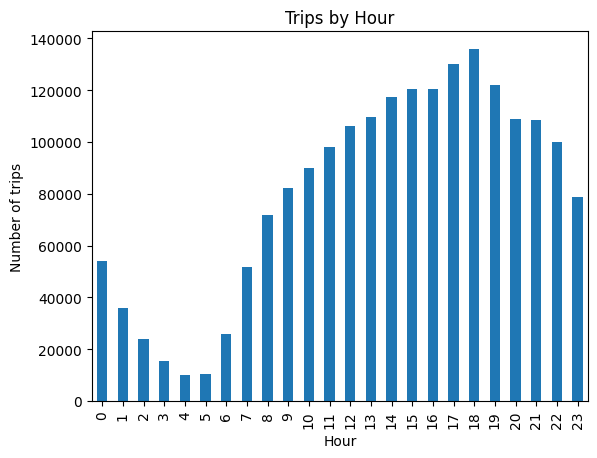

Busiest hour: 18
Number of trips: 135934


In [290]:
# Visualise the number of trips per hour and find the busiest hour
hours = pd.to_datetime(df["tpep_pickup_datetime"]).dt.hour
hourly_trips = hours.value_counts().reindex(range(24), fill_value=0)

hourly_trips.plot(kind="bar", title="Trips by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of trips")
plt.show()

print("Busiest hour:", hourly_trips.idxmax())
print("Number of trips:", hourly_trips.max())


Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [291]:
# Scale up the number of trips

# Fill in the value of your sampling fraction and use that to scale up the numbers
sample_fraction = 0.05

top_5_sampled = hourly_trips.nlargest(5)
top_5_estimated = (top_5_sampled / sample_fraction).round().astype(int)

top_5_results = pd.DataFrame({
    "sampled_trips": top_5_sampled,
    "estimated_actual_trips": top_5_estimated
})
top_5_results.index.name = "pickup_hour"

display(top_5_results)

,sampled_trips,estimated_actual_trips
pickup_hour,,
18,135934,2718680
17,130053,2601060
19,122012,2440240
15,120301,2406020
16,120287,2405740


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

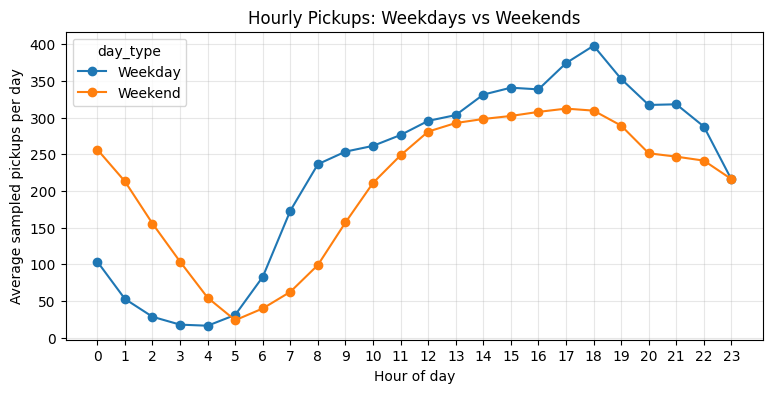

In [ ]:
# Compare traffic trends for the week days and weekends
pickup_time = pd.to_datetime(df["tpep_pickup_datetime"])

traffic = pd.DataFrame({
    "date": pickup_time.dt.date,
    "hour": pickup_time.dt.hour,
    "day_type": np.where(pickup_time.dt.dayofweek < 5, "Weekday", "Weekend")
})

hourly_counts = traffic.groupby(["day_type", "hour"]).size().unstack(fill_value=0)
days = traffic.groupby("day_type")["date"].nunique()
average_per_day = hourly_counts.div(days, axis=0)

average_per_day.T.plot(kind="line", marker="o", figsize=(9, 4))
plt.xlabel("Hour of day")
plt.ylabel("Average sampled pickups per day")
plt.title("Hourly Pickups: Weekdays vs Weekends")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?

#Taxi demand is more in the evening in all the days. It is lowest at morning 5'o clock during all the days.

#Tax demand is less in weekend compared to weekdays during days.

#During weekend in the night taxi demand is more than weekdays

**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

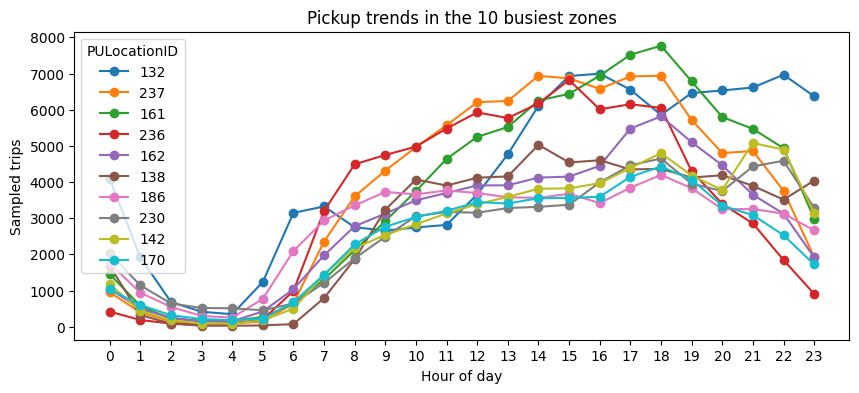

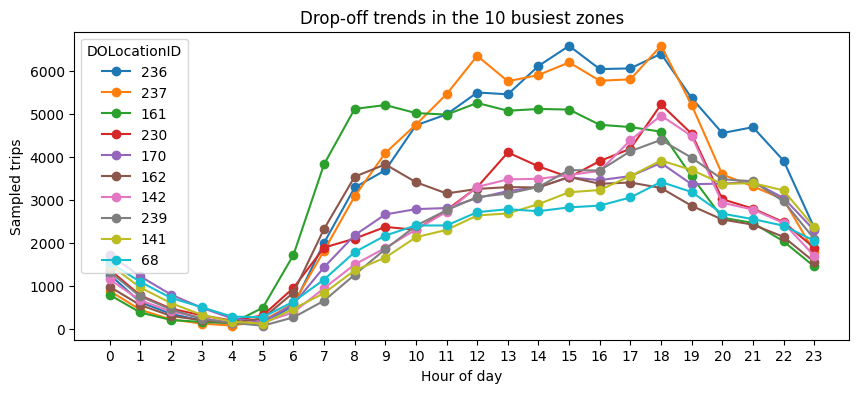

In [294]:
# Find top 10 pickup and dropoff zones
for zone_col, time_col, label in [
    ("PULocationID", "tpep_pickup_datetime", "Pickup"),
    ("DOLocationID", "tpep_dropoff_datetime", "Drop-off")
]:
    data = analysis_df_merged[[zone_col, time_col]].copy()
    data["hour"] = pd.to_datetime(data[time_col]).dt.hour
    hourly = data.groupby([zone_col, "hour"]).size().unstack(fill_value=0)
    hourly = hourly.reindex(columns=range(24), fill_value=0)
    top10 = hourly.sum(axis=1).nlargest(10).index

    hourly.loc[top10].T.plot(figsize=(10, 4), marker="o",
                             title=f"{label} trends in the 10 busiest zones")
    plt.xlabel("Hour of day")
    plt.ylabel("Sampled trips")
    plt.xticks(range(24))
    plt.show()


**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [295]:
# Find the top 10 and bottom 10 pickup/dropoff ratios
pickups = analysis_df_merged["PULocationID"].value_counts()
dropoffs = analysis_df_merged["DOLocationID"].value_counts()

ratio = (pickups / dropoffs).dropna().rename("pickup_dropoff_ratio")
display(ratio.nlargest(10))
display(ratio.nsmallest(10))

70     9.534292
132    4.912751
138    2.915051
186    1.583206
114    1.376068
43     1.375027
249    1.329976
162    1.258195
161    1.200834
100    1.191688
Name: pickup_dropoff_ratio, dtype: float64

1      0.008646
27     0.025000
257    0.027848
251    0.029412
156    0.034483
115    0.040000
198    0.040658
112    0.043468
37     0.044902
265    0.045102
Name: pickup_dropoff_ratio, dtype: float64

**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [296]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones

for zone, time in [("PULocationID", "tpep_pickup_datetime"),
                   ("DOLocationID", "tpep_dropoff_datetime")]:
    night = analysis_df_merged[pd.to_datetime(
        analysis_df_merged[time]).dt.hour.isin([23, 0, 1, 2, 3, 4])]
    display(night[zone].value_counts().head(10))

PULocationID
79     15988
132    13828
249    12942
48     10247
148     9981
114     9137
230     8128
186     6457
164     6197
138     6196
Name: count, dtype: int64

DOLocationID
79     9151
48     7509
170    6800
107    6278
68     6225
141    5948
263    5592
249    5507
230    5051
239    5035
Name: count, dtype: int64

Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

In [297]:
# Filter for night hours (11 PM to 5 AM)
hours = pd.to_datetime(analysis_df_merged["tpep_pickup_datetime"]).dt.hour
revenue = analysis_df_merged.groupby(hours.isin([23, 0, 1, 2, 3, 4]))["total_amount"].sum()
display(revenue.rename({True: "Night", False: "Day"}) / revenue.sum())

tpep_pickup_datetime
Day      0.887142
Night    0.112858
Name: total_amount, dtype: float64

##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

In [298]:
# Analyse the fare per mile per passenger for different passenger counts
x = analysis_df[analysis_df["passenger_count"] > 0]
(x["fare_amount"] / x["trip_distance"] / x["passenger_count"]).groupby(x["passenger_count"]).mean()

passenger_count
1.0    10.916044
2.0     6.437866
3.0     3.914177
4.0     4.329384
5.0     1.704814
6.0     1.347655
dtype: float64

**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

In [ ]:
# Compare the average fare per mile for different days and for different times of the day
fare_per_mile = analysis_df["fare_amount"] / analysis_df["trip_distance"]
pickup = pd.to_datetime(analysis_df["tpep_pickup_datetime"])

display(fare_per_mile.groupby(pickup.dt.hour).mean().rename("Fare per mile by hour"))
display(fare_per_mile.groupby(pickup.dt.day_name()).mean().rename("Fare per mile by day"))

tpep_pickup_datetime
0     10.704356
1     11.216520
2      9.784715
3     10.662114
4     13.653720
5     15.193702
6     11.059338
7     10.309983
8     10.301685
9     10.335988
10    10.668255
11    10.937141
12    12.161362
13    11.924959
14    11.610768
15    12.749667
16    13.847094
17    11.877678
18    11.462724
19    11.920780
20     9.544069
21     9.553618
22    10.010840
23    10.763508
Name: Fare per mile by hour, dtype: float64

tpep_pickup_datetime
Friday       10.926406
Monday       10.972739
Saturday     10.838153
Sunday       12.631913
Thursday     11.310701
Tuesday      11.377104
Wednesday    11.117179
Name: Fare per mile by day, dtype: float64

**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

In [ ]:
# Compare fare per mile for different vendors
display(fare_per_mile.groupby([analysis_df["VendorID"], pickup.dt.hour])
        .mean().unstack().round(2))

tpep_pickup_datetime,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
VendorID,,,,,,,,,,,,,,,,,,,,,,,,
1,6.81,7.06,6.90,6.51,7.46,7.04,6.63,7.19,8.07,8.39,8.42,8.71,8.83,8.74,8.67,8.82,8.83,8.66,8.50,7.93,7.47,7.30,7.04,6.96
2,11.85,12.44,10.67,11.90,15.72,18.58,12.97,11.60,11.20,11.11,11.55,11.80,13.43,13.16,12.72,14.22,15.71,13.03,12.49,13.26,10.22,10.25,10.90,11.91


**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


In [301]:
# Defining distance tiers
tiers = pd.cut(analysis_df["trip_distance"], [0, 2, 5, float("inf")],
               labels=["Up to 2 miles", "2–5 miles", "Over 5 miles"])

display(fare_per_mile.groupby([analysis_df["VendorID"], tiers],
                              observed=True).mean().unstack().round(2))


trip_distance,Up to 2 miles,2–5 miles,Over 5 miles
VendorID,,,
1,9.93,6.38,4.42
2,17.94,6.55,4.50


##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

In [302]:
#  Analyze tip percentages based on distances, passenger counts and pickup times
tip_pct = 100 * analysis_df["tip_amount"] / analysis_df["fare_amount"]
distance_tier = pd.cut(analysis_df["trip_distance"], [0, 2, 5, float("inf")],
                       labels=["Up to 2 mi", "2–5 mi", "Over 5 mi"])

display(tip_pct.groupby(distance_tier, observed=True).mean().round(2))
display(tip_pct.groupby(analysis_df["passenger_count"]).mean().round(2))
display(tip_pct.groupby(pickup.dt.hour).mean().round(2))

trip_distance
Up to 2 mi    22.42
2–5 mi        18.77
Over 5 mi     17.59
dtype: float64

passenger_count
0.0    20.06
1.0    20.94
2.0    19.73
3.0    19.04
4.0    17.40
5.0    20.50
6.0    20.59
dtype: float64

tpep_pickup_datetime
0     20.55
1     20.64
2     20.68
3     20.50
4     18.28
5     17.47
6     18.47
7     19.60
8     20.04
9     19.69
10    19.23
11    19.18
12    19.13
13    19.05
14    19.03
15    19.00
16    20.93
17    24.37
18    22.24
19    22.18
20    21.51
21    21.51
22    21.30
23    20.68
dtype: float64

Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

In [ ]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%



**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

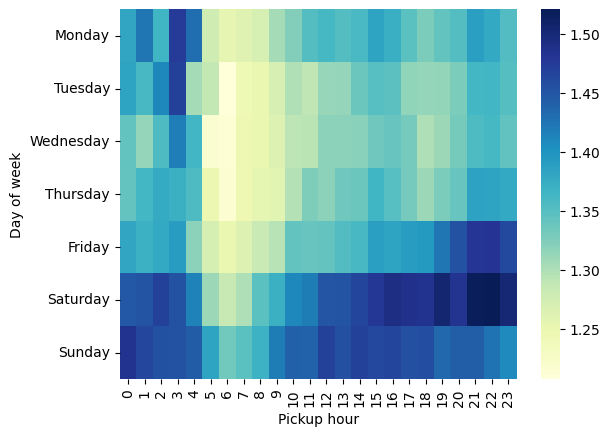

In [303]:
# See how passenger count varies across hours and days
passenger_time = analysis_df.assign(
    day=pickup.dt.day_name(), hour=pickup.dt.hour
).pivot_table(index="day", columns="hour", values="passenger_count", aggfunc="mean")

passenger_time = passenger_time.reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)
sns.heatmap(passenger_time, cmap="YlGnBu")
plt.xlabel("Pickup hour")
plt.ylabel("Day of week")
plt.show()



**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

In [ ]:
# How does passenger count vary across zones



In [ ]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.



Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

In [ ]:
# How often is each surcharge applied?



## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

The analysis shows that taxi demand changes by hour and day. Pickups are higher in the evening, while demand is lowest around 5 AM. 
Weekday and weekend patterns are also different. The company should schedule more taxis during busy hours and fewer during quiet hours. 
Drivers should use alternative routes when the analysis shows that a route is slow. This can reduce waiting time and help drivers complete more trips.

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

The pickup analysis shows that some zones have more demand than others. More taxis should be placed near the busiest pickup zones, especially before busy hours. During the night, taxis should be positioned near the zones with the most night pickups. The company should also watch the pickup and drop-off balance in each zone. If many taxis drop passengers in a zone but few passengers start trips there, taxis may need to move to a busier nearby zone.

**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

The analysis shows that fare amount generally increases with trip distance and duration. Average fare per mile can also differ by hour, day, distance, and vendor. The company should use these results to review its pricing and compare its rates with other providers